# Data Profiling Report - Member A

## 1. Scenario
An online grocery/retail retailer wants to monitor customer satisfaction across its products using customer reviews. This dataset is suitable because it intentionally contains real-world data-quality issues—missing values scattered across nearly every column, duplicate listings, inconsistent currency and discount formats, and invalid ratings—that must be diagnosed and handled before any satisfaction analysis can be trusted. The retailer wants to know which products receive the most negative feedback and how potential quality issues can be flagged early.

## 2. Data Source
**Source**: Kaggle

**Dataset Name**: Amazon products reviews dataset uncleaned

**Author**: Satyaki Das

**URL**: https://www.kaggle.com/datasets/satyakidas07/amazon-products-reviews-dataset-uncleaned

**Method**: Downloaded the `.xlsx` file directly from Kaggle and uploaded it to Google Colab. The data is loaded using `pandas.read_excel()`.

In [2]:
import pandas as pd
import numpy as np


df = pd.read_excel("Amazon_Products_Reviews_Dataset_UNCLEANED.xlsx", sheet_name="Amazon_Data_Raw")


df.head()

,product_id,product_name,category,Discounted_Price (INR),actual_price,discount_percentage,rating,Rating Count,about_product,user_id,user_name,review_id,review_title,review_content,IMG_LINK,product_link
0,B08SMJT55F,boAt Stone 250 Portable Wireless Speaker with ...,Electronics|HomeAudio|Speakers|BluetoothSpeakers,"₹1,199","₹3,990",70%,4.2,"2,908",Power- Get ready to be enthralled by the 5W RM...,"AHL435VQHZZXB545DXGLIZSACFOQ,AG6OEN75DD6ADCNOY...","Devashish Gautam,Vishakha,Sunny Tanna,Dr.Suman...","RLXE2MCKLCYMB,R39DFUZXNDFQ4,R30U7W2G83AI48,R2X...","Strudy, Awesome connectivity........but bass i...",The LED light is vibrant with multiple form se...,https://m.media-amazon.com/images/I/51J45Dcgkt...,https://www.amazon.in/boAt-Stone-250-Playback-...
1,B07F6GXNPB,EUREKA FORBES EUROCLEAN PAPER VACUUM CLEANER D...,"Home&Kitchen|Kitchen&HomeAppliances|Vacuum,Cl...",₹253,₹500,49%,4.3,"2,664",Special Anti-Microbial(Biocide Treated) Paper ...,"AEAHCVLMYLKLICSIKCTUS54NVQ2A,AFRIWQJKFSDZKTRTU...","Lulzdrone,KRISH,Harsh Shah,Harsh,HaPa,Inderjee...","R2K8VZSTF6Y1UH,R30LKPXEPE0CZE,R2714DP5UNSOQ,R1...","Bigger size,Superb.,Vacuum Bag,Price is reason...",These are the biggest one their models use and...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Eureka-Forbes-Euroclean-...
2,B08TTRVWKY,MILTON Smart Egg Boiler 360-Watts (Transparent...,Home&Kitchen|Kitchen&HomeAppliances|SmallKitch...,"₹1,099","₹1,899",42%,4.3,"1,811",3 Boiling Modes - The advanced appliance from ...,"AH2NLR3ZG7SADP6RTRU5PDZUBKYQ,AEDHYDNNCKCAOWK4...","Tapan Dutta,Seerat Dar,Saravana Kumar K N,Prad...","R1SPFVN2778DYH,R2GUT54B310MIN,R2WBP8YTLS3OPJ,R...","Nice good,Easy to use,Good , however little co...","Like it,Awesome product 😊,Follow the instructi...",https://m.media-amazon.com/images/I/41yrqUum9E...,https://www.amazon.in/MILTON-Smart-Egg-Boiler-...
3,B01MQ2A86A,"Logitech M331 Silent Plus Wireless Mouse, 2.4G...",Computers&Accessories|Accessories&Peripherals|...,NaN,"₹1,645",21%,4.6,"12,375",Quieter Click: Logitech’s SilentTouch Technolo...,"AE6TTPY5R4YW3XHTPGX6CGHLMVGA,AG5CBSM4UJ7KPPFIQ...","Awesome Shopper,Suresh madaka,Amazon Customer,...","R17S7JVWFH1X6W,R1HINIS5AG6PXD,R3VZFLZVFVZ13G,R...","Good but the scroll is now damaged,Nice,Noisel...",- excellent piece of wireless mouse- reasonabl...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Logitech-Silent-Wireless...
4,B08GM5S4CQ,Havells Instanio 10 Litre Storage Water Heater...,NaN,"₹6,990","₹14,290",51%,4.4,"1,771",Suitable for high-rise buildings and pressure ...,"AGUM6DLWGQ2LOM4MCKXEXKBXHXCQ,AELFZZK6GYFN3YA6T...","Amazon Customer,Gaurav,khalil shaikh,Aman Seti...","R3N1KWPD82KCJH,RUP7RE9R1GMG7,R1EM1ELIZK4UQO,R1...",Good product but attention needed in packing a...,"For this price range product design, look, spe...",https://m.media-amazon.com/images/I/31-XtyZy0I...,https://www.amazon.in/Havells-Instanio-Storage...


In [3]:

missing_count = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage (%)": missing_pct.round(2)
})


missing_table[missing_table["Missing Count"] > 0].sort_values("Missing Percentage (%)", ascending=False)

,Missing Count,Missing Percentage (%)
Rating Count,27,1.81
rating,25,1.67
Discounted_Price (INR),22,1.47
category,22,1.47
discount_percentage,22,1.47
actual_price,22,1.47
about_product,22,1.47
product_name,19,1.27
IMG_LINK,19,1.27
product_link,19,1.27


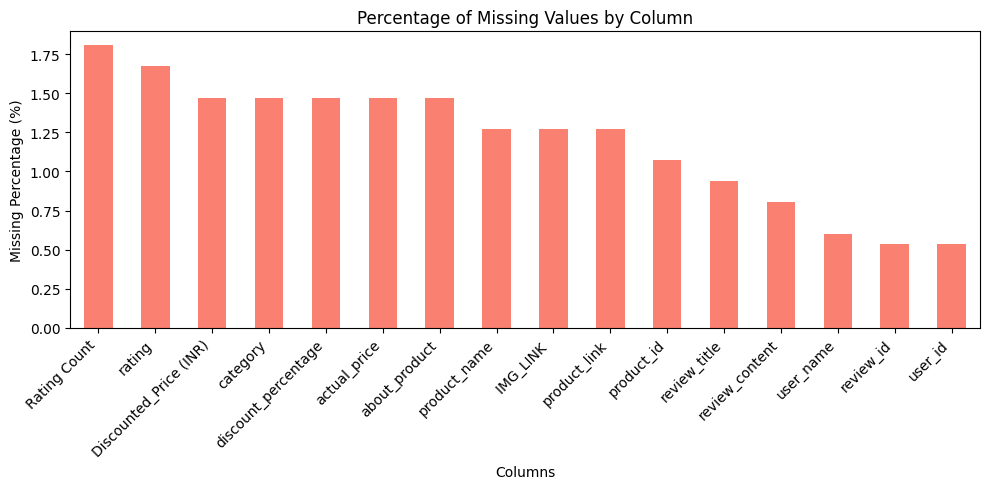

In [4]:
import matplotlib.pyplot as plt

missing_pct = (df.isnull().sum() / len(df)) * 100
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)

plt.figure(figsize=(10, 5))
missing_pct.plot(kind='bar', color='salmon')
plt.title('Percentage of Missing Values by Column')
plt.ylabel('Missing Percentage (%)')
plt.xlabel('Columns')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### Missing Values Analysis
From the table above, we can see:
Columns like `Review Content` and `Review Title` have missing values because many users only leave a star rating without writing any text.

`User Name` / `Reviewer Name` may be missing due to anonymous reviews or incomplete user profiles.

`Discount` or `Rating` might be missing if the product information was not fully updated by the seller.

In [5]:
df.columns = df.columns.str.strip()

rating_cols = [col for col in df.columns if 'rating' in col.lower() or 'score' in col.lower()]

if rating_cols:
    target_col = rating_cols[0]
    print(f"Found rating column: '{target_col}'")


    df_cleaned = df.dropna(subset=[target_col]).copy()

    text_cols = [col for col in df_cleaned.columns if "review" in col.lower() or "title" in col.lower()]
    for col in text_cols:
        df_cleaned[col] = df_cleaned[col].fillna("No text provided")

    print("Review text processing complete!")
else:
    print("Warning: No column containing 'rating' or 'score' was found.")


if 'Rating Count' in df_cleaned.columns:

    df_cleaned['Rating Count'] = pd.to_numeric(df_cleaned['Rating Count'], errors='coerce')
    df_cleaned['Rating Count'] = df_cleaned['Rating Count'].fillna(df_cleaned['Rating Count'].median())


df_cleaned = df_cleaned.fillna("Unknown")

print("Remaining missing values after full cleaning:")
print(df_cleaned.isnull().sum().sum())


Found rating column: 'rating'
Review text processing complete!
Remaining missing values after full cleaning:
0


### Handling Missing Values & Reasoning

Based on the missing value analysis, I applied the following strategies to ensure the dataset is fully cleaned:

1. **Dropping rows where `rating` is missing (Drop)**:
   The star rating is the primary metric for measuring customer satisfaction. Rows without a rating cannot answer the core business question (identifying negative feedback), so they were safely dropped.

2. **Filling missing text fields `review_title` and `review_content` (Impute)**:
   I filled missing values in these columns with the placeholder `"No text provided"` rather than dropping them. This preserves the valid rating data in those rows. Furthermore, an empty review is a common user behavior (e.g., leaving only a star rating), and the absence of text is itself meaningful.

3. **Handling `Rating Count` (Impute)**:
   Since `Rating Count` is a numerical field representing the number of reviews, I filled its missing values (19 missing) with the **median** of the column. Using the median instead of the mean prevents the imputation from being skewed by extreme outliers. I also ensured the column was converted to a numeric data type.

4. **Handling remaining categorical fields with `"Unknown"` (Impute)**:
   For the remaining metadata columns like `product_name` and `user_name`, I filled missing values with the string `"Unknown"`. This ensures data completeness and allows the dataset to be used for further analysis without dropping valuable rows just because a minor field is missing.

5. **Column name cleaning**:
   I stripped leading and trailing spaces from all column names to prevent future code errors.

The final output confirms that there are **0 missing values** remaining in the cleaned dataset (`df_cleaned`).